# 1. Understanding the Berkeley Hate Speech Dataset


## 1.1 Load the dataset and check its dimensions

- **pd.read_parquet()** reads the Berkeley Parquet file into a pandas DataFrame named `df`.
- **df.shape** returns `(rows, columns)`. It is an attribute, so it uses no parentheses.


In [2]:
import pandas as pd

df = pd.read_parquet("measuring_hate_speech.parquet")
df.shape

(135556, 143)

## 1.2 Count unique comments and annotators

- `comment_id` identifies the comment being rated. `annotator_id` identifies the person who rated it.
- **nunique()** counts the distinct, non-missing IDs in each selected column.
- **to_frame()** displays the two counts in a table with the heading “Unique count”.


In [3]:
df[["comment_id", "annotator_id"]].nunique().to_frame("Unique count")

,Unique count
comment_id,39565
annotator_id,7912


## 1.3 Inspect how different annotators rated one comment

We select one comment rated by multiple annotators, display its text once, and compare the ratings side by side in a table.

- **groupby()** groups the rows by `comment_id`.
- **nunique()** counts the distinct annotators for each comment.
- `example_id` stores the first comment ID with at least two different annotators.
- **loc[]** selects the rows for that comment. **iloc[0]** selects its text from the first row.
- `hatespeech` records each annotator’s judgment: 0 = no, 1 = unclear, 2 = yes.
- `hate_speech_score` is the published score for the comment. We display it alongside the individual judgments to see how the two differ.


In [4]:
annotator_counts = df.groupby("comment_id")["annotator_id"].nunique()
example_id = annotator_counts[annotator_counts >= 2].index[0]
example_rows = df.loc[df["comment_id"] == example_id]

print(example_rows["text"].iloc[0])
example_rows[["comment_id", "annotator_id", "hatespeech", "hate_speech_score"]]

White people are trash.


,comment_id,annotator_id,hatespeech,hate_speech_score
1064,1,3330,0.0,0.46
23298,1,962,0.0,0.46
50410,1,8185,0.0,0.46
70119,1,712,0.0,0.46


# 2. Data Quality Checks Before Combining Ratings


## 2.1 Check for repeated ratings by the same annotator

We check whether any combination of `comment_id` and `annotator_id` appears more than once. This matters because counting a repeated row as another vote could change a comment’s final label.

- **duplicated()** compares the two ID columns together and marks each occurrence after the first as `True`.
- **sum()** counts the marked rows.


In [5]:
df.duplicated(subset=["comment_id", "annotator_id"]).sum()

np.int64(0)

## 2.2 Check for missing IDs, text, ratings and scores

Before combining the ratings, we check which rows have the information needed to identify a comment, count a vote and compare it with Berkeley’s score.

- `required_columns` lists the five fields we are checking.
- **isna()** marks each missing value.
- **sum()** counts the marked values in each column.
- **to_frame()** displays the counts as a table.


In [6]:
required_columns = ["comment_id", "annotator_id", "text", "hatespeech", "hate_speech_score"]

df[required_columns].isna().sum().to_frame("Missing values")

,Missing values
comment_id,0
annotator_id,0
text,0
hatespeech,0
hate_speech_score,0


## 2.3 Verify the recorded hate-speech votes

The expected vote codes are 0 (no), 1 (unclear) and 2 (yes). We display every observed value and its count so that any unexpected code is visible.

- **value_counts()** counts how many annotation rows contain each vote.
- **sort_index()** arranges the rows by vote code.
- **to_frame()** displays the counts in a table.


In [7]:
df["hatespeech"].value_counts().sort_index().to_frame("Recorded votes")

,Recorded votes
hatespeech,
0.0,80624
1.0,8911
2.0,46021


## 2.4 Check text and score consistency within each comment

- **groupby()** groups all annotations with the same `comment_id`.
- **nunique()** counts how many distinct texts and severity scores appear within each group. `distinct_per_comment` stores these counts.
- **gt(1)** flags a comment if it has more than one value for a field.
- **sum()** counts the flagged comments for each field. **to_frame()** displays the result as a table.


In [8]:
distinct_per_comment = df.groupby("comment_id")[["text", "hate_speech_score"]].nunique()

distinct_per_comment.gt(1).sum().to_frame("Comments with conflicting values")

,Comments with conflicting values
text,0
hate_speech_score,0


# 3. Build the Comment-Level Dataset


## 3.1 Combine individual votes into one row per comment

- **pd.crosstab()** counts how many times each comment received each vote. `vote_counts` stores these counts, with zero wherever a comment received no votes of that type.
- **rename()** gives the vote codes readable names: `votes_no`, `votes_unclear` and `votes_yes`.
- **groupby()** and **first()** keep one text and one published score per comment. The previous check confirmed that both fields are consistent within each comment.
- **join()** matches the vote counts to the text and score using `comment_id`. **reset_index()** makes `comment_id` a regular column.
- `comments_df` holds the comment-level dataset. **head()** displays its first five rows.


In [9]:
vote_counts = pd.crosstab(df["comment_id"], df["hatespeech"]).rename(
    columns={0: "votes_no", 1: "votes_unclear", 2: "votes_yes"}
)

comments_df = (
    df.groupby("comment_id")[["text", "hate_speech_score"]]
    .first()
    .join(vote_counts)
    .reset_index()
)

comments_df.head()

,comment_id,text,hate_speech_score,votes_no,votes_unclear,votes_yes
0,1,White people are trash.,0.46,4,0,0
1,2,"You've caught the big gay, it's known to be ai...",0.03,1,0,2
2,3,"I'm not saying you said that, I'm just saying ...",-1.29,0,1,2
3,4,Donald Trump. Yeet myself off a building onto ...,-0.24,0,1,1
4,5,Fabrice Fabrice is ostensibly black or black/l...,-2.84,3,0,0


## 3.2 Assign a comment label and measure annotator agreement

Our project assigns `hate_speech` when more than half of all votes are yes and `no_hate_speech` when more than half are no. All other outcomes receive `ambiguous`, including ties and unclear majorities. Unclear votes count toward the total.

- `n_valid_votes` records how many ratings the comment received. **sum(axis=1)** adds the three vote counts across each row.
- `agreement_ratio` is the fraction of voters who chose the most common response. **max(axis=1)** finds the largest of the three counts.
- `hate_label` stores the project label. **loc[]** assigns it to rows meeting each majority condition.
- **head()** displays the first five results so we can check them against the vote counts.


In [10]:
votes = comments_df[["votes_no", "votes_unclear", "votes_yes"]]
comments_df["n_valid_votes"] = votes.sum(axis=1)
comments_df["agreement_ratio"] = votes.max(axis=1) / comments_df["n_valid_votes"]

half_votes = comments_df["n_valid_votes"] / 2
comments_df["hate_label"] = "ambiguous"
comments_df.loc[votes["votes_yes"] > half_votes, "hate_label"] = "hate_speech"
comments_df.loc[votes["votes_no"] > half_votes, "hate_label"] = "no_hate_speech"

comments_df[["comment_id", "n_valid_votes", "agreement_ratio", "hate_label"]].head()

,comment_id,n_valid_votes,agreement_ratio,hate_label
0,1,4,1.000000,no_hate_speech
1,2,3,0.666667,hate_speech
2,3,3,0.666667,hate_speech
3,4,2,0.500000,ambiguous
4,5,3,1.000000,no_hate_speech


## 3.3 Summarize the comment-level labels

We count the comments in each class and calculate their percentage of the full comment-level dataset.

- **value_counts()** counts the comments assigned to each label.
- **len()** gives the total number of comments used to calculate each percentage.
- **round(2)** displays the percentages to two decimal places.
- **pd.DataFrame()** puts the counts and percentages in one table.


In [11]:
label_counts = comments_df["hate_label"].value_counts()

pd.DataFrame({
    "Comments": label_counts,
    "Share of comments (%)": (label_counts / len(comments_df) * 100).round(2)
})

,Comments,Share of comments (%)
hate_label,,
no_hate_speech,24487,61.89
hate_speech,8089,20.44
ambiguous,6989,17.66


## 3.4 Add target-group annotations to each comment

We calculate the share of annotators who marked each of the eight broad target groups for a comment.

- `target_columns` lists the eight group indicators from the original dataset.
- **groupby()** collects the annotations for each `comment_id`.
- **mean()** calculates the share of recorded responses marked `True`. For example, if 3 of 4 annotators marked religion, `target_religion_share` is 0.75.
- **add_suffix()** adds `_share` to distinguish these proportions from the original yes/no indicators.
- **map()** uses `comment_id` to copy each share into the matching row of `comments_df`.
- **head()** previews the first five comments.


In [12]:
target_columns = [
    "target_race", "target_religion", "target_origin", "target_gender",
    "target_sexuality", "target_age", "target_disability", "target_politics"
]

target_shares = df.groupby("comment_id")[target_columns].mean().add_suffix("_share")

for column in target_shares:
    comments_df[column] = comments_df["comment_id"].map(target_shares[column])

comments_df[["comment_id", *target_shares.columns]].head()

,comment_id,target_race_share,target_religion_share,target_origin_share,target_gender_share,target_sexuality_share,target_age_share,target_disability_share,target_politics_share
0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


## 3.5 Summarize language ratings for each comment

The dataset has nine language dimensions rated on a 0–4 scale. We keep the average recorded rating for each dimension so the processed dataset preserves more detail than the overall hate-speech label alone.

- `rating_columns` lists the nine dimensions.
- **groupby()** collects the ratings for each `comment_id`.
- **mean()** averages the available ratings within each dimension. If a dimension has no recorded rating for a comment, its average stays missing.
- **add_suffix()** adds `_mean` to each new column name.
- **map()** matches each average to the correct comment using `comment_id`.
- **head()** previews four of the nine dimensions to keep the table readable.


In [13]:
rating_columns = [
    "sentiment", "respect", "insult", "humiliate", "status",
    "dehumanize", "violence", "genocide", "attack_defend"
]

rating_means = df.groupby("comment_id")[rating_columns].mean().add_suffix("_mean")

for column in rating_means:
    comments_df[column] = comments_df["comment_id"].map(rating_means[column])

comments_df[[
    "comment_id", "insult_mean", "humiliate_mean", "dehumanize_mean", "violence_mean"
]].head()

,comment_id,insult_mean,humiliate_mean,dehumanize_mean,violence_mean
0,1,3.250000,2.750000,2.750000,0.250000
1,2,3.333333,2.666667,1.666667,0.666667
2,3,3.000000,2.666667,1.666667,0.000000
3,4,2.000000,2.500000,2.000000,0.500000
4,5,1.666667,1.666667,0.666667,0.000000


# 4. Text Cleaning


## 4.1 Normalize whitespace and preserve the original comment

The `text` column keeps the original wording. We create `text_clean` for NLP by replacing repeated spaces, tabs and line breaks with a single space and removing spaces at the beginning and end. This preserves words, negation, capitalization, punctuation and emojis.

- **str.replace()** uses the regular expression `\s+` to match one or more whitespace characters and replace them with one space.
- **str.strip()** removes leading and trailing whitespace.
- **ne()** compares the original and cleaned text. `changed` records which comments were affected.
- **head(3)** previews up to three changed comments so we can inspect what the cleaning actually did.


In [14]:
comments_df["text_clean"] = (
    comments_df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

changed = comments_df["text_clean"].ne(comments_df["text"])
print("Comments with whitespace changes:", changed.sum())

comments_df.loc[changed, ["comment_id", "text", "text_clean"]].head(3)

Comments with whitespace changes: 2683


,comment_id,text,text_clean
15,19,Won't happen. Birth rates are down. Women wan...,Won't happen. Birth rates are down. Women want...
23,29,I'm absolutely for equal rights for all people...,I'm absolutely for equal rights for all people...
37,49,I am just gonna have siblings coming over and ...,I am just gonna have siblings coming over and ...


## 4.2 Replace web links and usernames with placeholders

We replace web links with `URL` and @usernames with `USER` in `text_clean`. This lets the model recognize that a link or mention was present without learning a particular account name. The original comment stays in `text` for comparison and highlighting.

- `url_pattern` matches links beginning with `http://`, `https://` or `www.`.
- `username_pattern` matches @usernames. It skips the `@` inside ordinary email addresses.
- **str.replace()** applies each pattern to the cleaned text.
- **str.contains()** finds original comments containing a link or mention so we can preview relevant examples.


In [15]:
url_pattern = r"(?i)\b(?:https?://|www\.)[^\s<>]*[\w/#]"
username_pattern = r"(?<![\w@])@\w+"

comments_df["text_clean"] = (
    comments_df["text_clean"]
    .str.replace(url_pattern, "URL", regex=True)
    .str.replace(username_pattern, "USER", regex=True)
)

has_link_or_mention = (
    comments_df["text"].str.contains(url_pattern, regex=True)
    | comments_df["text"].str.contains(username_pattern, regex=True)
)

comments_df.loc[has_link_or_mention, ["comment_id", "text", "text_clean"]].head(3)

,comment_id,text,text_clean
3241,4031,@RealAlMunajjid: This leftist Jew disguised as...,USER: This leftist Jew disguised as Greek is s...
4334,5387,lmao is this real? >Walter(Owen's Grandp >@wal...,lmao is this real? >Walter(Owen's Grandp >USER...
4841,6008,I just figured out how to get Ass-backwards Al...,I just figured out how to get Ass-backwards Al...


## 4.3 Check for empty and repeated cleaned comments

- `text_key` is a comparison version of `text_clean`. **str.casefold()** lets us match text regardless of capitalization while preserving capitalization in `text_clean`.
- **eq("")** identifies comments that are empty after whitespace cleaning.
- **value_counts()** counts how many times each non-empty comparison text appears.
- **gt(1)** identifies texts shared by multiple comment records. **sum()** counts how many distinct texts meet that condition.


In [16]:
text_key = comments_df["text_clean"].str.casefold()
empty_text = text_key.eq("")
text_counts = text_key[~empty_text].value_counts()

pd.Series({
    "Empty comments after cleaning": empty_text.sum(),
    "Distinct non-empty texts appearing more than once": text_counts.gt(1).sum()
}, name="Count").to_frame()

,Count
Empty comments after cleaning,0
Distinct non-empty texts appearing more than once,48


# 5. Prepare the Training, Validation and Test Sets


## 5.1 Assign splits while keeping matching comments together

We aim for approximately 80% training, 10% validation and 10% test data. Training data teaches the model, validation data helps us choose settings, and test data is reserved for final evaluation.

- `text_key` groups comments whose cleaned text matches after ignoring capitalization.
- **GroupShuffleSplit()** randomly divides whole groups. The first split reserves 20% of groups. The second divides those reserved groups equally between validation and test.
- **split()** produces row positions for each subset. **iloc[]** selects rows by those positions.
- `random_state=42` makes the assignment reproducible when we rerun the notebook with the same data and row order.
- **value_counts()** shows the actual number of comments assigned to each split. The percentages can vary slightly because we split groups.


In [17]:
from sklearn.model_selection import GroupShuffleSplit

first_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_pos, reserved_pos = next(first_split.split(comments_df, groups=text_key))

reserved = comments_df.iloc[reserved_pos]
second_split = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_pos, test_pos = next(second_split.split(reserved, groups=text_key.iloc[reserved_pos]))

comments_df["split"] = "train"
comments_df.loc[reserved.index[val_pos], "split"] = "validation"
comments_df.loc[reserved.index[test_pos], "split"] = "test"

comments_df["split"].value_counts().to_frame("Comments")

,Comments
split,
train,31655
test,3957
validation,3953


## 5.2 Verify the split and compare label percentages

- **groupby(text_key)** groups comments whose cleaned text matches after ignoring capitalization.
- **nunique()** counts how many splits each group appears in. **gt(1)** flags groups that cross a split boundary, and **sum()** counts them. The expected result is zero.
- **pd.crosstab()** compares the labels across splits. `normalize="index"` calculates proportions within each split.
- **mul(100)** converts proportions to percentages, and **round(2)** keeps the table readable.


In [18]:
splits_per_text = comments_df.groupby(text_key)["split"].nunique()
print("Cleaned-text groups appearing in multiple splits:", splits_per_text.gt(1).sum())

pd.crosstab(
    comments_df["split"],
    comments_df["hate_label"],
    normalize="index"
).mul(100).round(2)

Cleaned-text groups appearing in multiple splits: 0


hate_label,ambiguous,hate_speech,no_hate_speech
split,,,
test,17.99,20.39,61.61
train,17.65,20.34,62.01
validation,17.48,21.30,61.22


# 6. Export the Processed Dataset


## 6.1 Save the comment-level dataset

The processed file contains one row per comment, with the original and cleaned text, vote counts, agreement ratio, derived label, Berkeley severity score, target-group shares, language ratings and split assignment.

- `splits_per_text` contains the number of splits occupied by each cleaned-text group.
- **eq(1)** checks that each group appears in exactly one split. **all()** checks that this holds for every group.
- **assert** stops the cell before saving if any group crosses a split boundary.
- **to_parquet()** writes the processed dataset to a separate file. `index=False` leaves out the pandas row index because `comment_id` already identifies each comment.


In [19]:
assert splits_per_text.eq(1).all(), "A cleaned-text group appears in multiple splits."

processed_file = "berkeley_hate_speech_processed.parquet"
comments_df.to_parquet(processed_file, index=False)

print(f"Saved {len(comments_df):,} comments to {processed_file}")

Saved 39,565 comments to berkeley_hate_speech_processed.parquet


## 6.2 Create the data dictionary

The data dictionary contains one row per column in the processed dataset, with its name and meaning.

- `definitions` stores a description for each column. The two loops describe the target-group shares and language ratings using the same column lists we used to create them.
- **pd.DataFrame()** builds the dictionary in the same column order as the processed dataset.
- **to_csv()** saves the dictionary as a separate file that can be opened in Excel.
- **head()** previews the first five entries.


In [20]:
definitions = {
    "comment_id": "Original Berkeley comment identifier.",
    "text": "Original English comment.",
    "text_clean": "Comment with normalized whitespace, links replaced by URL, and usernames replaced by USER.",
    "hate_speech_score": "Published Berkeley severity score. Higher values indicate greater estimated hate-speech severity.",
    "votes_no": "Number of annotators who voted no on hate speech.",
    "votes_unclear": "Number of annotators who voted unclear on hate speech.",
    "votes_yes": "Number of annotators who voted yes on hate speech.",
    "n_valid_votes": "Total number of no, unclear and yes votes for the comment.",
    "agreement_ratio": "Largest of the three vote counts divided by total valid votes.",
    "hate_label": "hate_speech for a strict yes majority, no_hate_speech for a strict no majority, otherwise ambiguous.",
    "split": "Assigned dataset split: train, validation or test."
}

for column in target_columns:
    group = column.removeprefix("target_")
    definitions[f"{column}_share"] = (
        f"Fraction of recorded responses marking {group} as a target group, from 0 to 1."
    )

rating_meanings = {
    "sentiment": "positive to negative sentiment",
    "respect": "respectful to disrespectful language",
    "insult": "degree of insult",
    "humiliate": "degree of humiliation",
    "status": "portrayal as superior to portrayal as inferior",
    "dehumanize": "degree of dehumanization",
    "violence": "endorsement of violence",
    "genocide": "endorsement of genocide",
    "attack_defend": "defending to attacking"
}

for column in rating_columns:
    definitions[f"{column}_mean"] = f"Mean annotator rating (0–4): {rating_meanings[column]}."

data_dictionary = pd.DataFrame({
    "Column": comments_df.columns,
    "Meaning": [definitions[column] for column in comments_df.columns]
})

data_dictionary.to_csv("data_dictionary.csv", index=False, encoding="utf-8-sig")
data_dictionary.head()

,Column,Meaning
0,comment_id,Original Berkeley comment identifier.
1,text,Original English comment.
2,hate_speech_score,Published Berkeley severity score. Higher valu...
3,votes_no,Number of annotators who voted no on hate speech.
4,votes_unclear,Number of annotators who voted unclear on hate...


# 7. Explore the Training Data


## 7.1 Compare severity scores across the three labels

- **loc[]** selects the training comments and stores them in `train_df`.
- **boxplot()** plots `hate_speech_score` separately for each `hate_label`. The line inside each box is the median. The box covers the middle 50% of scores in that group.
- `showfliers=False` hides individual outlier markers to keep the graph readable. All training scores are included when calculating the boxes.


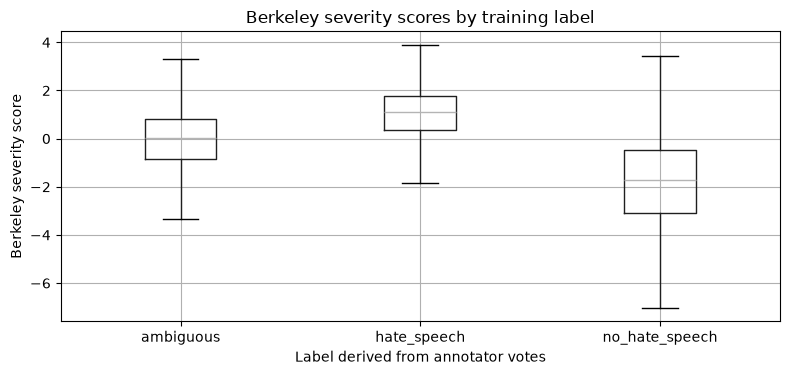

In [21]:
import matplotlib.pyplot as plt

train_df = comments_df.loc[comments_df["split"] == "train"]

ax = train_df.boxplot(
    column="hate_speech_score",
    by="hate_label",
    showfliers=False,
    figsize=(8, 4)
)
ax.figure.suptitle("")
ax.set_title("Berkeley severity scores by training label")
ax.set_xlabel("Label derived from annotator votes")
ax.set_ylabel("Berkeley severity score")
plt.tight_layout()
plt.show()

# 8. Train and Validate the Hate-Speech Classifier


## 8.1 Train a TF-IDF baseline on comment text

We use `text_clean` as the input and `hate_label` as the target. We keep all three labels so we can measure how well the model recognizes comments where annotators reached no clear yes or no majority.

- **TfidfVectorizer()** converts individual words and adjacent word pairs into numerical features. For example, “not welcome” can be a feature alongside “not” and “welcome”.
- **LogisticRegression()** learns how those features relate to the three labels.
- **make_pipeline()** connects the vectorizer and classifier. **fit()** learns both the vocabulary and the classifier using training comments only.
- **predict()** assigns a label to each validation comment.
- **classification_report()** summarizes precision, recall and F1 for each label. `Comments` is the number of validation comments with that recorded label.


In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.pipeline import make_pipeline

validation_df = comments_df.loc[comments_df["split"] == "validation"]

baseline_model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2),
    LogisticRegression(max_iter=1000)
)
baseline_model.fit(train_df["text_clean"], train_df["hate_label"])

validation_predictions = baseline_model.predict(validation_df["text_clean"])

report = classification_report(
    validation_df["hate_label"],
    validation_predictions,
    output_dict=True,
    zero_division=0
)

results = pd.DataFrame(report).T.loc[
    ["no_hate_speech", "hate_speech", "ambiguous", "macro avg"]
]
results.columns = ["Precision", "Recall", "F1", "Comments"]
results["Comments"] = results["Comments"].astype(int)
results.round(3)

,Precision,Recall,F1,Comments
no_hate_speech,0.715,0.935,0.810,2420
hate_speech,0.628,0.501,0.557,842
ambiguous,0.248,0.042,0.072,691
macro avg,0.530,0.493,0.480,3953


## 8.2 Identify which labels the baseline confuses

Rows show the recorded labels and columns show the model’s predictions. Each cell is a count of validation comments. The diagonal contains correct predictions.

- `label_order` keeps the rows and columns in the same order.
- **confusion_matrix()** counts each combination of recorded and predicted labels.
- **pd.DataFrame()** displays the counts as a table. **pd.Index()** names the axes so we can distinguish recorded labels from predictions.


In [23]:
from sklearn.metrics import confusion_matrix

label_order = ["no_hate_speech", "hate_speech", "ambiguous"]

matrix = confusion_matrix(
    validation_df["hate_label"],
    validation_predictions,
    labels=label_order
)

pd.DataFrame(
    matrix,
    index=pd.Index(label_order, name="Recorded"),
    columns=pd.Index(label_order, name="Predicted")
)

Predicted,no_hate_speech,hate_speech,ambiguous
Recorded,,,
no_hate_speech,2262,109,49
hate_speech,381,422,39
ambiguous,521,141,29


## 8.3 Test whether class weighting improves hate-speech detection

The training set contains more `no_hate_speech` comments than either of the other labels. With `class_weight="balanced"`, logistic regression gives examples from less frequent classes more weight during training.

- **clone()** creates an untrained copy of the baseline pipeline with the same TF-IDF and classifier settings.
- **set_params()** changes only the classifier’s class weighting.
- **fit()** trains the weighted model. **predict()** generates its validation predictions.
- **classification_report()** calculates the metrics for comparison.
- **sum()** counts recorded hate-speech comments that each model predicted as `no_hate_speech`.


In [24]:
from sklearn.base import clone

weighted_model = clone(baseline_model).set_params(
    logisticregression__class_weight="balanced"
)
weighted_model.fit(train_df["text_clean"], train_df["hate_label"])
weighted_predictions = weighted_model.predict(validation_df["text_clean"])

actual_labels = validation_df["hate_label"]
comparison = {}

for name, predictions in [
    ("Baseline", validation_predictions),
    ("Class-weighted", weighted_predictions),
]:
    scores = classification_report(
        actual_labels, predictions, output_dict=True, zero_division=0
    )
    comparison[name] = {
        "Hate predicted as no hate": (
            (actual_labels == "hate_speech") & (predictions == "no_hate_speech")
        ).sum(),
        "Hate precision": scores["hate_speech"]["precision"],
        "Hate recall": scores["hate_speech"]["recall"],
        "Ambiguous recall": scores["ambiguous"]["recall"],
        "Macro F1": scores["macro avg"]["f1-score"],
    }

pd.DataFrame.from_dict(comparison, orient="index").round(3)

,Hate predicted as no hate,Hate precision,Hate recall,Ambiguous recall,Macro F1
Baseline,381,0.628,0.501,0.042,0.480
Class-weighted,138,0.555,0.602,0.278,0.538


## 8.4 Test word and character n-grams together

We keep the class-weighted logistic regression and the existing word features. We add character sequences of 3 to 5 characters within word boundaries.

- **make_union()** combines the word and character TF-IDF features into one feature matrix.
- **clone()** copies the settings of the word vectorizer and weighted classifier.
- **TfidfVectorizer()** with `analyzer="char_wb"` extracts short character sequences within padded word boundaries.
- **fit()** learns from the training comments. **predict()** produces predictions for the same validation comments used in the previous experiment.
- **classification_report()** calculates the metrics for the new row in our comparison table.


In [25]:
from sklearn.pipeline import make_union

word_char_model = make_pipeline(
    make_union(
        clone(weighted_model.named_steps["tfidfvectorizer"]),
        TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2)
    ),
    clone(weighted_model.named_steps["logisticregression"])
)

word_char_model.fit(train_df["text_clean"], train_df["hate_label"])
word_char_predictions = word_char_model.predict(validation_df["text_clean"])

scores = classification_report(
    actual_labels, word_char_predictions, output_dict=True, zero_division=0
)
comparison["Class-weighted + character n-grams"] = {
    "Hate predicted as no hate": (
        (actual_labels == "hate_speech") & (word_char_predictions == "no_hate_speech")
    ).sum(),
    "Hate precision": scores["hate_speech"]["precision"],
    "Hate recall": scores["hate_speech"]["recall"],
    "Ambiguous recall": scores["ambiguous"]["recall"],
    "Macro F1": scores["macro avg"]["f1-score"],
}

pd.DataFrame.from_dict(comparison, orient="index").round(3)

,Hate predicted as no hate,Hate precision,Hate recall,Ambiguous recall,Macro F1
Baseline,381,0.628,0.501,0.042,0.480
Class-weighted,138,0.555,0.602,0.278,0.538
Class-weighted + character n-grams,134,0.585,0.612,0.300,0.556


# 9. Predict Hate-Speech Severity


## 9.1 Estimate the Berkeley severity score from comment text

We compare two ways to predict severity. The baseline gives every comment the median training score. The regression model uses the words and character patterns in each comment to estimate its individual score.

- `text_features` is the fitted TF-IDF feature extractor from Section 8.4. **transform()** applies its training vocabulary to the comments.
- **Ridge()** creates a linear regression model with regularization, which limits how strongly individual text features influence the prediction.
- **fit()** learns from the training comments and their Berkeley scores. **predict()** estimates scores for the validation comments.
- **median()** gives the constant baseline prediction.
- **mean_absolute_error()** measures the average distance between estimated and recorded scores. Lower is better. The result is in Berkeley score units.


In [26]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error

text_features = word_char_model.steps[0][1]
severity_model = Ridge(solver="lsqr")

severity_model.fit(
    text_features.transform(train_df["text_clean"]),
    train_df["hate_speech_score"]
)

severity_predictions = severity_model.predict(
    text_features.transform(validation_df["text_clean"])
)

actual_scores = validation_df["hate_speech_score"]
median_score = train_df["hate_speech_score"].median()

pd.DataFrame({
    "Validation MAE": {
        "Training median": (actual_scores - median_score).abs().mean(),
        "Text-based ridge regression": mean_absolute_error(actual_scores, severity_predictions)
    }
}).round(3)

,Validation MAE
Training median,1.653
Text-based ridge regression,1.086


# 10. Identify Groups Referenced in a Comment


## 10.1 Check training examples for each target group

A comment can refer to several groups, so we examine each group separately. We use a strict-majority rule: a share above 0.5 means most recorded responses marked the group, a share below 0.5 means most did not, and exactly 0.5 is a tie.

- `group_shares` selects the eight target-group share columns from the training set.
- **gt()**, **lt()** and **eq()** check whether each share is above, below or equal to 0.5.
- **sum()** counts the matching comments for each group. **isna()** identifies comments with no recorded share for that group.
- **sort_values()** lists the groups with the most positive training examples first.


In [27]:
group_shares = train_df[[f"{column}_share" for column in target_columns]]

group_support = pd.DataFrame({
    "Majority marked": group_shares.gt(0.5).sum(),
    "Majority unmarked": group_shares.lt(0.5).sum(),
    "Tied": group_shares.eq(0.5).sum(),
    "Missing": group_shares.isna().sum()
})

group_support.sort_values("Majority marked", ascending=False)

,Majority marked,Majority unmarked,Tied,Missing
target_gender_share,10307,19754,1594,0
target_race_share,8203,21610,1842,0
target_sexuality_share,5154,25469,1032,0
target_origin_share,4851,25459,1345,0
target_religion_share,4560,26378,717,0
target_politics_share,1165,29665,825,0
target_disability_share,654,30761,240,0
target_age_share,521,30836,298,0


## 10.2 Train and validate the eight target-group classifiers

Each classifier uses comment text to predict whether a majority of annotators marked its group. This prediction is separate from the hate-speech verdict.

- **transform()** reuses the fitted word and character TF-IDF features from Section 8.4. We calculate the features once for all eight classifiers.
- **notna()** and **ne(0.5)** select comments with a recorded, decisive share for the current group. **gt(0.5)** creates its yes/no label.
- **LogisticRegression()** uses balanced class weights because some groups have relatively few positive examples.
- **fit()** trains each classifier. **predict()** evaluates it on validation comments with decisive votes for that group.
- **precision_recall_fscore_support()** calculates precision, recall and F1 for the positive label. Support counts the validation comments where a majority marked the group.
- `group_models` stores the trained classifiers for later use in the interface.


In [28]:
from sklearn.metrics import precision_recall_fscore_support

train_features = text_features.transform(train_df["text_clean"])
validation_features = text_features.transform(validation_df["text_clean"])

group_models = {}
group_results = []

for target in target_columns:
    group = target.removeprefix("target_")
    train_share = train_df[f"{target}_share"]
    validation_share = validation_df[f"{target}_share"]

    train_mask = train_share.notna() & train_share.ne(0.5)
    validation_mask = validation_share.notna() & validation_share.ne(0.5)

    model = LogisticRegression(class_weight="balanced", max_iter=1000)
    model.fit(
        train_features[train_mask.to_numpy()],
        train_share[train_mask].gt(0.5)
    )
    group_models[group] = model

    actual = validation_share[validation_mask].gt(0.5)
    predicted = model.predict(validation_features[validation_mask.to_numpy()])

    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=[True], zero_division=0
    )
    group_results.append({
        "Group": group,
        "Precision": precision[0],
        "Recall": recall[0],
        "F1": f1[0],
        "Positive validation comments": support[0]
    })

pd.DataFrame(group_results).set_index("Group").sort_values("F1", ascending=False).round(3)

,Precision,Recall,F1,Positive validation comments
Group,,,,
gender,0.837,0.881,0.859,1239
religion,0.801,0.864,0.832,583
race,0.816,0.801,0.809,1068
sexuality,0.795,0.821,0.808,653
origin,0.699,0.823,0.756,598
disability,0.632,0.652,0.642,92
politics,0.317,0.510,0.391,143
age,0.287,0.409,0.338,66


# 11. Predict Language Behavior Ratings


## 11.1 Predict four behavior ratings from comment text

Each behavior has an average annotator rating on a 0–4 scale. A comment can score highly on several behaviors, so we estimate each score separately.

- `behavior_models` stores the four trained models. `train_features` and `validation_features` reuse the text features calculated in Section 10.2.
- **notna()** selects comments with a recorded rating for the behavior being evaluated.
- **Ridge()** creates a regression model. **fit()** learns from training comments, and **predict()** estimates ratings for validation comments.
- **median()** gives each behavior its own training baseline. **mean_absolute_error()** measures the average prediction error in rating points.
- `MAE reduction (%)` shows how much the text model improves on the median baseline. A positive value means the text model has lower error.


In [29]:
behavior_models = {}
behavior_results = []

for behavior in ["insult", "humiliate", "dehumanize", "violence"]:
    train_rating = train_df[f"{behavior}_mean"]
    validation_rating = validation_df[f"{behavior}_mean"]
    train_mask = train_rating.notna()
    validation_mask = validation_rating.notna()

    model = Ridge(solver="lsqr")
    model.fit(train_features[train_mask.to_numpy()], train_rating[train_mask])
    behavior_models[behavior] = model

    actual = validation_rating[validation_mask]
    predicted = model.predict(validation_features[validation_mask.to_numpy()])
    baseline_mae = (actual - train_rating.median()).abs().mean()
    model_mae = mean_absolute_error(actual, predicted)

    behavior_results.append({
        "Behavior": behavior,
        "Median baseline MAE": baseline_mae,
        "Text model MAE": model_mae,
        "MAE reduction (%)": 100 * (1 - model_mae / baseline_mae)
    })

pd.DataFrame(behavior_results).set_index("Behavior").round(3)

,Median baseline MAE,Text model MAE,MAE reduction (%)
Behavior,,,
insult,0.967,0.700,27.598
humiliate,0.949,0.696,26.656
dehumanize,0.913,0.748,18.092
violence,0.709,0.617,12.956


# 12. Evaluate Feedback While Typing


## 12.1 Compare two endings after the same group mention

We simulate a user typing “People with disabilities” and then completing the comment with either a supportive or an exclusionary ending. We inspect the whole draft at each stage.

- `typing_check` contains the draft stages and their exact text. Both endings continue from the shared opening.
- **predict()** returns the verdict that our selected classifier would give each draft.
- **predict_proba()** gives a score for each possible label. We display the `hate_speech` score to see whether the wording changes the model’s response even when the verdict stays the same.
- `classes_` gives the label order used by the classifier. **index()** locates the hate-speech column.


In [ ]:
typing_check = pd.DataFrame({
    "Stage": ["First word", "Shared opening", "Supportive ending", "Exclusionary ending"],
    "Draft": [
        "People",
        "People with disabilities",
        "People with disabilities belong here.",
        "People with disabilities should be excluded."
    ]
})

typing_check["Verdict"] = word_char_model.predict(typing_check["Draft"])

hate_column = list(word_char_model.classes_).index("hate_speech")
typing_check["Hate class score"] = (
    word_char_model.predict_proba(typing_check["Draft"])[:, hate_column].round(3)
)

typing_check

,Stage,Draft,Verdict,Hate class score
0,First word,People,no_hate_speech,0.018
1,Shared opening,People with disabilities,no_hate_speech,0.060
2,Supportive ending,People with disabilities belong here.,no_hate_speech,0.079
3,Exclusionary ending,People with disabilities should be excluded.,no_hate_speech,0.101


## 12.2 Test whether changing one word changes the verdict

We compare paired comments about four groups. Within each pair, only the final word changes. The intended result is a higher hate-class score for the exclusionary sentence and a verdict that distinguishes the two endings.

- `groups` contains the group mentions used in this check.
- **predict()** returns the verdict for each complete sentence.
- **predict_proba()** returns the class scores. `hate_column` selects the hate-speech score identified in Section 12.1.
- `Score change` is the exclusionary score minus the inclusive score. A positive value means the score moved in the intended direction, even if the verdict stayed the same.


In [31]:
groups = ["People with disabilities", "Muslims", "Immigrants", "Women"]
pair_results = []

for group in groups:
    drafts = [
        f"{group} should be included.",
        f"{group} should be excluded."
    ]
    verdicts = word_char_model.predict(drafts)
    hate_scores = word_char_model.predict_proba(drafts)[:, hate_column]

    pair_results.append({
        "Group mention": group,
        "Included verdict": verdicts[0],
        "Excluded verdict": verdicts[1],
        "Included score": hate_scores[0],
        "Excluded score": hate_scores[1],
        "Score change": hate_scores[1] - hate_scores[0]
    })

pd.DataFrame(pair_results).set_index("Group mention").round(3)

,Included verdict,Excluded verdict,Included score,Excluded score,Score change
Group mention,,,,,
People with disabilities,no_hate_speech,no_hate_speech,0.088,0.101,0.013
Muslims,no_hate_speech,no_hate_speech,0.077,0.090,0.012
Immigrants,no_hate_speech,no_hate_speech,0.056,0.070,0.014
Women,no_hate_speech,no_hate_speech,0.060,0.075,0.015


## 12.3 Check training evidence for “included” and “excluded”

We count training comments containing each word or phrase, grouped by the recorded label. We also check which terms were available as whole-word features in the trained classifier.

- `terms` lists the two words and their corresponding two-word phrases.
- **CountVectorizer()** uses a fixed vocabulary for this diagnostic. With `binary=True`, a term counts once per comment even if it appears several times.
- **fit_transform()** creates one column per term. **groupby()** and **sum()** count matching comments within each training label.
- `vocabulary_` contains the word features learned in Section 8.4. A term absent from this vocabulary can still contribute through character n-grams.


In [32]:
from sklearn.feature_extraction.text import CountVectorizer

terms = ["included", "excluded", "be included", "be excluded"]
counter = CountVectorizer(vocabulary=terms, ngram_range=(1, 2), binary=True)

term_counts = pd.DataFrame(
    counter.fit_transform(train_df["text_clean"]).toarray(),
    columns=terms,
    index=train_df.index
)

term_summary = term_counts.groupby(train_df["hate_label"]).sum().T
term_summary["Total training comments"] = term_summary.sum(axis=1)

word_vocabulary = baseline_model.named_steps["tfidfvectorizer"].vocabulary_
term_summary["In word vocabulary"] = [term in word_vocabulary for term in terms]

term_summary

hate_label,ambiguous,hate_speech,no_hate_speech,Total training comments,In word vocabulary
included,2,3,27,32,True
excluded,0,0,3,3,True
be included,0,0,3,3,True
be excluded,0,0,0,0,False


## 12.4 Measure how each word influences a draft’s hate-speech score

We score the complete draft, then remove one word at a time and score it again. This is called leave-one-word-out analysis.

- **split()** separates this example sentence into words.
- **enumerate()** gives each word a position so we remove one occurrence at a time.
- **join()** rebuilds each version after one word is removed.
- **predict_proba()** scores the full draft and all shortened versions in one call.
- `Score drop` equals the full-draft score minus the score without that word. A positive value means removing the word lowered the hate-speech score.


In [33]:
draft = "People with disabilities should be excluded."
words = draft.split()

shortened_drafts = [
    " ".join(words[:i] + words[i + 1:])
    for i, word in enumerate(words)
]

hate_scores = word_char_model.predict_proba([draft, *shortened_drafts])[:, hate_column]

word_effects = pd.DataFrame({
    "Removed word": words,
    "Score without word": hate_scores[1:],
    "Score drop": hate_scores[0] - hate_scores[1:]
})

print(f"Full-draft hate-speech score: {hate_scores[0]:.3f}")
word_effects.sort_values("Score drop", ascending=False).round(3)

Full-draft hate-speech score: 0.101


,Removed word,Score without word,Score drop
3,should,0.079,0.022
5,excluded.,0.079,0.022
1,with,0.099,0.003
4,be,0.099,0.002
2,disabilities,0.111,-0.010
0,People,0.143,-0.041


## 12.5 Test how negation changes the prediction

We compare four complete drafts about the same group. Adding “not” should lower the hate-class score for “excluded” and raise it for “included.” Checking both directions helps us see whether the model responds to the meaning of the phrase.

- `negation_check` stores the four drafts and their intended meanings.
- **predict()** returns the verdict for each draft.
- **predict_proba()** gives the hate-class score so we can see changes even when the verdict stays the same.


In [34]:
negation_check = pd.DataFrame({
    "Draft": [
        "People with disabilities should be excluded.",
        "People with disabilities should not be excluded.",
        "People with disabilities should be included.",
        "People with disabilities should not be included."
    ],
    "Intended meaning": [
        "Supports exclusion",
        "Rejects exclusion",
        "Supports inclusion",
        "Rejects inclusion"
    ]
})

drafts = negation_check["Draft"]
negation_check["Verdict"] = word_char_model.predict(drafts)
negation_check["Hate class score"] = (
    word_char_model.predict_proba(drafts)[:, hate_column].round(3)
)

negation_check

,Draft,Intended meaning,Verdict,Hate class score
0,People with disabilities should be excluded.,Supports exclusion,no_hate_speech,0.101
1,People with disabilities should not be excluded.,Rejects exclusion,no_hate_speech,0.076
2,People with disabilities should be included.,Supports inclusion,no_hate_speech,0.088
3,People with disabilities should not be included.,Rejects inclusion,no_hate_speech,0.066


# 13. Evaluate Posting Guidance


## 13.1 Compare thresholds for showing “No hate-speech concern detected”

A hate-speech verdict produces a warning. An ambiguous verdict produces a review prompt. For a no-hate verdict, we compare several minimum model scores for showing reassurance. If the no-hate score falls below the threshold, the interface shows “Review before posting.”

- **predict_proba()** returns the model’s class scores for validation comments. `no_hate_column` selects the score belonging to `no_hate_speech`.
- `reassure` identifies comments that receive the reassuring message. A threshold of 0.00 reproduces the current verdict-only rule.
- **sum()** counts how many comments receive each message and how many recorded hate-speech comments receive reassurance.
- These thresholds are experimental settings. A score of 0.75 does not establish a 75% chance that a comment is safe to post.


In [35]:
no_hate_column = list(word_char_model.classes_).index("no_hate_speech")
no_hate_scores = word_char_model.predict_proba(validation_df["text_clean"])[:, no_hate_column]

no_hate_verdict = word_char_predictions == "no_hate_speech"
hate_warning = word_char_predictions == "hate_speech"
recorded_hate = validation_df["hate_label"].eq("hate_speech").to_numpy()

guidance_results = []

for threshold in [0.00, 0.60, 0.75, 0.90]:
    reassure = no_hate_verdict & (no_hate_scores >= threshold)
    review = ~(reassure | hate_warning)

    guidance_results.append({
        "No-hate threshold": threshold,
        "Reassurance messages": reassure.sum(),
        "Review prompts": review.sum(),
        "Hate warnings": hate_warning.sum(),
        "Recorded hate given reassurance": (recorded_hate & reassure).sum()
    })

pd.DataFrame(guidance_results).set_index("No-hate threshold")

,Reassurance messages,Review prompts,Hate warnings,Recorded hate given reassurance
No-hate threshold,,,,
0.00,2285,787,881,134
0.60,1506,1566,881,34
0.75,877,2195,881,9
0.90,231,2841,881,0


## 13.2 Evaluate the selected posting rule on held-out test comments

We selected the 0.60 threshold using validation data. We now apply it to the test set with the trained model and threshold fixed.

- **predict_proba()** calculates the three class scores for each test comment.
- **argmax(axis=1)** finds the highest-scoring class for each comment. `classes_` maps that position to its verdict.
- `test_guidance` starts with “Review before posting.” A hate-speech verdict receives a warning. A no-hate verdict receives reassurance only when its no-hate score reaches 0.60.
- **pd.crosstab()** counts the messages shown for each recorded label. Read across the `hate_speech` row to see how many received reassurance, review or a warning.


In [36]:
reassurance_threshold = 0.60
test_df = comments_df.loc[comments_df["split"] == "test"]

test_scores = word_char_model.predict_proba(test_df["text_clean"])
test_predictions = word_char_model.classes_[test_scores.argmax(axis=1)]

test_guidance = pd.Series("Review before posting", index=test_df.index, name="Message")
test_guidance.loc[test_predictions == "hate_speech"] = "Hate-speech warning"

reassure = (
    (test_predictions == "no_hate_speech")
    & (test_scores[:, no_hate_column] >= reassurance_threshold)
)
test_guidance.loc[reassure] = "No hate-speech concern detected"

pd.crosstab(test_df["hate_label"], test_guidance).reindex(
    index=label_order,
    columns=["No hate-speech concern detected", "Review before posting", "Hate-speech warning"],
    fill_value=0
)

Message,No hate-speech concern detected,Review before posting,Hate-speech warning
hate_label,,,
no_hate_speech,1380,864,194
hate_speech,42,277,488
ambiguous,159,346,207


# 14. Evaluate Severity and Category Predictions on the Test Set


## 14.1 Evaluate the severity score on unseen comments

We compare the trained severity model with the same training-median baseline used in validation. Both methods predict Berkeley severity scores for the same test comments.

- **transform()** converts test comments into text features using the vocabulary learned during training.
- **predict()** uses the trained regression model to estimate each comment’s severity.
- **mean_absolute_error()** measures the average distance between the estimated and recorded scores in Berkeley score units.
- `median_score` is the median severity from the training set. It gives us a fixed benchmark for judging whether the text helps.


In [37]:
test_features = text_features.transform(test_df["text_clean"])
test_severity = severity_model.predict(test_features)
actual_severity = test_df["hate_speech_score"]

pd.DataFrame({
    "Test MAE": {
        "Training median": (actual_severity - median_score).abs().mean(),
        "Text-based ridge regression": mean_absolute_error(actual_severity, test_severity)
    }
}).round(3)

,Test MAE
Training median,1.680
Text-based ridge regression,1.104


## 14.2 Evaluate target-group predictions on unseen comments

We evaluate each trained group classifier on test comments with a decisive annotation for that group. A share above 0.5 is positive, a share below 0.5 is negative, and a share of exactly 0.5 is a tie.

- `group_models` holds the eight trained classifiers. `test_features` contains the text features prepared in Section 14.1.
- **notna()** and **ne(0.5)** select comments with a recorded, decisive share for the current group.
- **predict()** applies the trained classifier to those comments.
- **precision_recall_fscore_support()** calculates precision, recall, F1 and the number of positive test comments for each group.
- **join()** places the earlier validation F1 beside the test results so we can compare performance on both splits.


In [38]:
group_test_results = []

for group, model in group_models.items():
    share = test_df[f"target_{group}_share"]
    decisive = share.notna() & share.ne(0.5)

    actual = share[decisive].gt(0.5)
    predicted = model.predict(test_features[decisive.to_numpy()])

    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=[True], zero_division=0
    )
    group_test_results.append({
        "Group": group,
        "Test precision": precision[0],
        "Test recall": recall[0],
        "Test F1": f1[0],
        "Positive test comments": support[0]
    })

validation_f1 = pd.DataFrame(group_results).set_index("Group")["F1"].rename("Validation F1")
group_test_table = pd.DataFrame(group_test_results).set_index("Group")

group_test_table.join(validation_f1).sort_values("Test F1", ascending=False).round(3)

,Test precision,Test recall,Test F1,Positive test comments,Validation F1
Group,,,,,
gender,0.830,0.870,0.850,1282,0.859
religion,0.815,0.873,0.843,545,0.832
race,0.820,0.806,0.813,1054,0.809
sexuality,0.773,0.799,0.786,612,0.808
origin,0.691,0.801,0.742,627,0.756
disability,0.552,0.654,0.599,81,0.642
politics,0.279,0.496,0.357,131,0.391
age,0.301,0.315,0.308,89,0.338


## 14.3 Evaluate behavior ratings on unseen comments

We evaluate insult, humiliation, dehumanization and violence separately. Each rating uses a 0–4 scale. The baseline for each behavior is its median rating in the training set.

- `behavior_models` contains the four trained regression models.
- **notna()** selects test comments with a recorded rating for the current behavior.
- **predict()** estimates that behavior rating from the comment’s text features.
- **mean_absolute_error()** measures the average error in rating points. Lower values indicate estimates closer to the recorded ratings.
- `MAE reduction (%)` shows how much the text model reduces error compared with predicting the training median for every comment.


In [39]:
behavior_test_results = []

for behavior, model in behavior_models.items():
    column = f"{behavior}_mean"
    rated = test_df[column].notna()
    actual = test_df.loc[rated, column]
    predicted = model.predict(test_features[rated.to_numpy()])

    training_median = train_df[column].median()
    baseline_mae = (actual - training_median).abs().mean()
    model_mae = mean_absolute_error(actual, predicted)

    behavior_test_results.append({
        "Behavior": behavior,
        "Test comments": len(actual),
        "Median baseline MAE": baseline_mae,
        "Text model MAE": model_mae,
        "MAE reduction (%)": 100 * (1 - model_mae / baseline_mae)
    })

pd.DataFrame(behavior_test_results).set_index("Behavior").round(3)

,Test comments,Median baseline MAE,Text model MAE,MAE reduction (%)
Behavior,,,,
insult,3957,0.971,0.696,28.298
humiliate,3957,0.966,0.704,27.075
dehumanize,3957,0.921,0.740,19.606
violence,3957,0.712,0.635,10.841


# 15. Save the Models for the Interface


## 15.1 Save the evaluated models and posting threshold

- `model_bundle` keeps the verdict classifier, severity model, eight group classifiers, four behavior models and the selected reassurance threshold together.
- The verdict pipeline already contains the fitted TF-IDF feature extractor shared by the other models.
- `url_pattern` and `username_pattern` preserve the exact matching rules used during text cleaning.
- **joblib.dump()** saves the bundle as one file. `compress=3` reduces its size.


In [40]:
import joblib

model_bundle = {
    "verdict_model": word_char_model,
    "severity_model": severity_model,
    "group_models": group_models,
    "behavior_models": behavior_models,
    "reassurance_threshold": reassurance_threshold,
    "url_pattern": url_pattern,
    "username_pattern": username_pattern,
}

model_file = "hate_speech_models.joblib"
joblib.dump(model_bundle, model_file, compress=3)
print(f"Saved {model_file}")

Saved hate_speech_models.joblib


## 15.2 Verify that the saved models reproduce the notebook outputs

We load the saved bundle and compare its predictions with the models still in the notebook. We use the same five cleaned comments for both.

- **joblib.load()** reads the model bundle from disk.
- **head()** selects five comments for this quick check.
- **predict_proba()** returns the verdict scores used by the posting rule.
- **transform()** applies the feature extractor stored inside the saved verdict pipeline.
- **predict()** produces the severity estimates, group tags and behavior ratings.
- **np.allclose()** compares numerical predictions, allowing tiny rounding differences. **np.array_equal()** checks that group tags match exactly.


In [41]:
import numpy as np

loaded = joblib.load(model_file)
sample = test_df["text_clean"].head(5)

saved_verdict = loaded["verdict_model"]
saved_features = saved_verdict.steps[0][1].transform(sample)
original_features = text_features.transform(sample)

checks = {
    "Verdict scores": np.allclose(
        saved_verdict.predict_proba(sample),
        word_char_model.predict_proba(sample)
    ),
    "Severity scores": np.allclose(
        loaded["severity_model"].predict(saved_features),
        severity_model.predict(original_features)
    ),
    "All eight group tags": all(
        np.array_equal(loaded["group_models"][name].predict(saved_features),
                       model.predict(original_features))
        for name, model in group_models.items()
    ),
    "All four behavior ratings": all(
        np.allclose(loaded["behavior_models"][name].predict(saved_features),
                    model.predict(original_features))
        for name, model in behavior_models.items()
    ),
    "Reassurance threshold": loaded["reassurance_threshold"] == reassurance_threshold,
}

pd.Series(checks, name="Matches notebook").to_frame()

,Matches notebook
Verdict scores,True
Severity scores,True
All eight group tags,True
All four behavior ratings,True
Reassurance threshold,True


# 16. Connect the Models to the Interface


## 16.1 Analyze one raw comment

- **analyse_comment()** takes the user’s text and the loaded model bundle. An empty input returns no result, so clearing the text box also clears the assessment.
- **split()** and **join()** normalize whitespace. **re.sub()** applies the saved URL and username rules used during training.
- **transform()** converts the cleaned comment into features once. The verdict, severity, group and behavior models all use those features.
- **predict_proba()** gives the verdict scores. **argmax()** identifies the highest-scoring label. The saved 0.60 threshold determines when a no-hate verdict receives reassurance.
- **predict()** produces the severity estimate, group tags and behavior ratings.
- `%%writefile` saves the function in `comment_analysis.py` so the interface can import it later.


In [42]:
%%writefile comment_analysis.py
import re


def analyse_comment(text, bundle):
    clean_text = " ".join(text.split())
    if not clean_text:
        return None

    clean_text = re.sub(bundle["url_pattern"], "URL", clean_text)
    clean_text = re.sub(bundle["username_pattern"], "USER", clean_text)

    pipeline = bundle["verdict_model"]
    features = pipeline[:-1].transform([clean_text])
    classifier = pipeline[-1]

    scores = classifier.predict_proba(features)[0]
    top_index = scores.argmax()
    verdict = classifier.classes_[top_index]

    guidance = "Review before posting"
    if verdict == "hate_speech":
        guidance = "Hate-speech warning"
    elif verdict == "no_hate_speech" and scores[top_index] >= bundle["reassurance_threshold"]:
        guidance = "No hate-speech concern detected"

    groups = [
        name for name, model in bundle["group_models"].items()
        if model.predict(features)[0]
    ]
    behaviors = {
        name: float(model.predict(features)[0])
        for name, model in bundle["behavior_models"].items()
    }

    return {
        "verdict": verdict,
        "posting_guidance": guidance,
        "severity": float(bundle["severity_model"].predict(features)[0]),
        "groups_referenced": groups,
        "behavior_ratings": behaviors,
    }

Overwriting comment_analysis.py


## 16.2 Test the interface function with a raw comment

- **analyse_comment()** runs the full prediction process using the saved models. `result` contains the outputs for one comment.
- We compare `result` with the output for a manually cleaned version of the same comment. Matching results confirm that this example behaves as expected.
- **pd.Series()** and **to_frame()** display the verdict, posting guidance, severity, group tags and behavior ratings in a readable table.
- **round()** shortens numeric values for display while preserving the original predictions in `result`.


In [ ]:
from comment_analysis import analyse_comment

raw_comment = "@alex   People with disabilities belong here. https://example.com"
expected_clean = "USER People with disabilities belong here. URL"

result = analyse_comment(raw_comment, loaded)
print("Matches cleaned example:", result == analyse_comment(expected_clean, loaded))

pd.Series({
    "Verdict": result["verdict"],
    "Posting guidance": result["posting_guidance"],
    "Estimated Berkeley severity": round(result["severity"], 2),
    "Possible groups referenced": ", ".join(result["groups_referenced"]) or "None predicted",
    **{
        f"Estimated {name} rating": round(value, 2)
        for name, value in result["behavior_ratings"].items()
    }
}, name="Model output").to_frame()

Matches cleaned example: True


,Model output
Verdict,no_hate_speech
Posting guidance,No hate-speech concern detected
Estimated Berkeley severity,-2.67
Possible groups referenced,"race, disability"
Estimated insult rating,1.44
Estimated humiliate rating,1.9
Estimated dehumanize rating,1.9
Estimated violence rating,0.83


## 16.3 Display the assessment as the user types

- **widgets.Textarea()** creates the comment box. `continuous_update=True` allows edits to trigger an update while typing.
- **observe()** calls **update_assessment()** whenever the text changes. `change["new"]` contains the current draft.
- **analyse_comment()** applies the saved models and posting rule to the entire draft, so earlier words are reconsidered as the sentence develops.
- **clear_output()** removes the previous assessment. Clearing the text box also clears the result.
- **display()** shows the input and output together in the notebook.


In [44]:
import ipywidgets as widgets
from IPython.display import display
import joblib
from comment_analysis import analyse_comment

loaded = joblib.load("hate_speech_models.joblib")

comment_box = widgets.Textarea(
    placeholder="Type or paste an English comment…",
    continuous_update=True,
    layout=widgets.Layout(width="100%", height="90px")
)
assessment_output = widgets.Output()

def update_assessment(change):
    result = analyse_comment(change["new"], loaded)

    with assessment_output:
        assessment_output.clear_output(wait=result is not None)
        if result is None:
            return

        print("Draft verdict:", result["verdict"].replace("_", " "))
        print("Posting guidance:", result["posting_guidance"])
        print("Estimated Berkeley severity:", round(result["severity"], 2))
        print("Possible groups referenced:", ", ".join(result["groups_referenced"]) or "None predicted")
        print("\nEstimated behavior ratings")
        for name, value in result["behavior_ratings"].items():
            print(f"{name}: {value:.2f}")

comment_box.observe(update_assessment, names="value")
display(comment_box, assessment_output)

Textarea(value='', layout=Layout(height='90px', width='100%'), placeholder='Type or paste an English comment…'…

Output()

# 17. Compare a Bidirectional GRU with the TF-IDF Classifier


## 17.1 Tokenize training comments and choose a sequence length

A BiGRU reads tokens in order. For example, “People should not be excluded.” becomes `["people", "should", "not", "be", "excluded", "."]`. Keeping “not” and its position matters for our negation experiment.

- **pd.read_parquet()** loads the cleaned text and saved split from our processed dataset.
- **str.lower()** converts text to lowercase. **str.findall()** extracts words, numbers and punctuation in their original order. The pattern keeps contractions such as “don't” together and preserves single-letter words such as “I”.
- **str.len()** counts the tokens in each training comment.
- **quantile()** finds the 95th-percentile length. We use it as our initial sequence limit so that at least 95% of training comments fit in full.
- **gt()** counts longer comments when combined with **sum()**. This tells us exactly how many training comments would need shortening at that limit.


In [45]:
import pandas as pd

sequence_df = pd.read_parquet(
    "berkeley_hate_speech_processed.parquet",
    columns=["text_clean", "split"]
)
train_text = sequence_df.loc[sequence_df["split"] == "train", "text_clean"]

token_pattern = r"\w+(?:['’]\w+)*|[^\w\s]"
train_tokens = train_text.str.lower().str.findall(token_pattern)
token_lengths = train_tokens.str.len()

sequence_length = int(token_lengths.quantile(0.95, interpolation="higher"))

pd.Series({
    "Training comments": len(train_tokens),
    "Median tokens per comment": token_lengths.median(),
    "Selected sequence length (95th percentile)": sequence_length,
    "Longest training comment (tokens)": token_lengths.max(),
    "Comments longer than the selected length": token_lengths.gt(sequence_length).sum()
}, name="Value").astype(int).to_frame()

,Value
Training comments,31655
Median tokens per comment,22
Selected sequence length (95th percentile),74
Longest training comment (tokens),157
Comments longer than the selected length,1544


## 17.2 Build the training vocabulary and encode one comment

Neural networks take numbers as input. We give each training token an integer ID and keep the IDs in the same order as the words. An ID identifies a token. Its numerical size has no meaning.

- **Counter()** counts how often each token occurs in the training comments. We give tokens seen at least twice their own IDs.
- `token_to_id` stores the vocabulary. ID `0` is reserved for padding and ID `1` for rare or unseen tokens. Known token IDs start at `2`.
- **encode_tokens()** keeps the first 74 tokens, looks up each ID using **get()**, and adds padding on the right until the sequence contains exactly 74 IDs.
- **pd.DataFrame()** displays the first 12 positions of one encoded comment so we can check the word-to-number mapping.


In [46]:
from collections import Counter

token_counts = Counter(token for tokens in train_tokens for token in tokens)
vocabulary = [token for token, count in token_counts.items() if count >= 2]
token_to_id = {token: index for index, token in enumerate(vocabulary, start=2)}

def encode_tokens(tokens):
    token_ids = [token_to_id.get(token, 1) for token in tokens[:sequence_length]]
    return token_ids + [0] * (sequence_length - len(token_ids))

example_tokens = train_tokens.iloc[0]
example_ids = encode_tokens(example_tokens)

print("Vocabulary size including padding and unknown:", len(token_to_id) + 2)
print("Encoded sequence length:", len(example_ids))

pd.DataFrame({
    "Token": (example_tokens + ["<PAD>"] * 12)[:12],
    "Token ID": example_ids[:12]
})

Vocabulary size including padding and unknown: 17208
Encoded sequence length: 74


,Token,Token ID
0,white,2
1,people,3
2,are,4
3,trash,5
4,.,6
5,<PAD>,0
6,<PAD>,0
7,<PAD>,0
8,<PAD>,0
9,<PAD>,0


## 17.3 Prepare the training and validation arrays

Each row in `X_train` contains one comment encoded as 74 token IDs. The value at the same position in `y_train` is that comment’s label. `X_val` and `y_val` follow the same structure for validation.

- **pd.read_parquet()** reads the label and split columns in the same row order as the text loaded in Section 17.1.
- **encode_tokens()** applies our existing training vocabulary to each comment. Validation words outside that vocabulary receive ID `1`.
- **np.array()** collects the encoded comments into an integer matrix.
- **map()** converts each verdict into a class ID. These class IDs are separate from the token IDs used for words and padding.


In [47]:
import numpy as np

label_df = pd.read_parquet(
    "berkeley_hate_speech_processed.parquet",
    columns=["split", "hate_label"]
)
label_to_id = {"no_hate_speech": 0, "hate_speech": 1, "ambiguous": 2}

val_text = sequence_df.loc[sequence_df["split"] == "validation", "text_clean"]
val_tokens = val_text.str.lower().str.findall(token_pattern)

X_train = np.array([encode_tokens(tokens) for tokens in train_tokens], dtype="int32")
X_val = np.array([encode_tokens(tokens) for tokens in val_tokens], dtype="int32")

y_train = label_df.loc[train_tokens.index, "hate_label"].map(label_to_id).to_numpy(dtype="int32")
y_val = label_df.loc[val_tokens.index, "hate_label"].map(label_to_id).to_numpy(dtype="int32")

pd.DataFrame({
    "Input shape": [X_train.shape, X_val.shape],
    "Label count": [len(y_train), len(y_val)]
}, index=["Training", "Validation"])

,Input shape,Label count
Training,"(31655, 74)",31655
Validation,"(3953, 74)",3953


## 17.4 Define the bidirectional GRU classifier

The model takes 74 token IDs as input and produces three class scores: no hate speech, hate speech and ambiguous.

- **Embedding()** learns a 64-number representation for each token. `mask_zero=True` tells the GRU to skip padding. In our five-token example, it processes the five real tokens and skips the 69 padding positions.
- **Bidirectional(GRU(32))** reads the comment in both directions. Each direction produces 32 values, which are combined into a 64-value representation of the comment.
- **Dense()** converts that representation into three class scores. Softmax makes the scores sum to one.
- **compile()** configures training. Sparse categorical cross-entropy accepts the integer labels we prepared in Section 17.3.
- **summary()** displays the architecture and parameter counts. Training starts in the next cell.


In [48]:
from tensorflow import keras

keras.utils.set_random_seed(42)

bigru_model = keras.Sequential([
    keras.Input(shape=(sequence_length,), dtype="int32"),
    keras.layers.Embedding(
        input_dim=len(token_to_id) + 2,
        output_dim=64,
        mask_zero=True
    ),
    keras.layers.Bidirectional(keras.layers.GRU(32)),
    keras.layers.Dense(len(label_to_id), activation="softmax")
], name="bigru_classifier")

bigru_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bigru_model.summary()

Model: "bigru_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 74, 64)         │     1,101,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        18,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,120,323 (4.27 MB)

 Trainable params: 1,120,323 (4.27 MB)

 Non-trainable params: 0 (0.00 B)

## 17.5 Train the BiGRU with class weighting and early stopping

We train on 31,655 comments and check validation loss after each epoch. One epoch is one pass through the training data.

- **compute_class_weight()** calculates a weight for each class from `y_train`. Less frequent classes receive more weight, following the same balancing principle as our selected TF-IDF classifier.
- **EarlyStopping()** stops training after two consecutive epochs without an improvement in validation loss. `restore_best_weights=True` restores the weights from the epoch with the lowest validation loss.
- **fit()** trains the model in batches of 64 comments for up to eight epochs. `bigru_history` stores the loss and accuracy from each epoch.


In [49]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes.tolist(), weights.tolist()))

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

bigru_history = bigru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    batch_size=64,
    epochs=8,
    callbacks=[early_stop]
)

Epoch 1/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 44s 76ms/step - accuracy: 0.5736 - loss: 0.9386 - val_accuracy: 0.6446 - val_loss: 0.8069
Epoch 2/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.6621 - loss: 0.7871 - val_accuracy: 0.6390 - val_loss: 0.8057
Epoch 3/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.7212 - loss: 0.6586 - val_accuracy: 0.6223 - val_loss: 0.8925
Epoch 4/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 36s 72ms/step - accuracy: 0.7788 - loss: 0.5267 - val_accuracy: 0.6200 - val_loss: 1.0212


## 17.6 Compare the trained BiGRU with the website classifier

- **predict()** produces predictions from each trained model. For the BiGRU, **argmax(axis=1)** selects the class with the highest score for each comment.
- **classification_report()** calculates accuracy, macro F1, and precision and recall for hate speech.
- `Hate predicted as no hate` counts comments labeled hate speech that received a no-hate verdict. Lower is better for this column.


In [50]:
import joblib
from sklearn.metrics import classification_report

website_model = joblib.load("hate_speech_models.joblib")["verdict_model"]
website_predictions = website_model.predict(val_text)

class_names = np.array(sorted(label_to_id, key=label_to_id.get))
actual = class_names[y_val]
bigru_predictions = class_names[bigru_model.predict(X_val, verbose=0).argmax(axis=1)]

model_results = {}
for name, predicted in [
    ("Website TF-IDF", website_predictions),
    ("BiGRU", bigru_predictions),
]:
    report = classification_report(actual, predicted, output_dict=True, zero_division=0)
    model_results[name] = {
        "Accuracy": report["accuracy"],
        "Macro F1": report["macro avg"]["f1-score"],
        "Hate precision": report["hate_speech"]["precision"],
        "Hate recall": report["hate_speech"]["recall"],
        "Hate predicted as no hate": ((actual == "hate_speech") & (predicted == "no_hate_speech")).sum()
    }

pd.DataFrame.from_dict(model_results, orient="index").round(3)

,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
Website TF-IDF,0.653,0.556,0.585,0.612,134
BiGRU,0.639,0.555,0.587,0.597,117


## 17.7 Test whether dropout improves the BiGRU

We train a fresh BiGRU with the same data and settings as the first run. The one architectural change is a dropout layer between the BiGRU and the classifier.

- **set_random_seed(42)** reuses the original seed for this comparison.
- **Dropout(0.30)** randomly sets 30% of the BiGRU output values to zero during training. This encourages the classifier to rely on several features. During prediction, all features are available.
- **EarlyStopping()** restores the weights from the epoch with the lowest validation loss.
- **fit()** trains the new model and stores its training history in `dropout_history`.


In [51]:
keras.utils.set_random_seed(42)

dropout_bigru = keras.Sequential([
    keras.Input(shape=(sequence_length,), dtype="int32"),
    keras.layers.Embedding(len(token_to_id) + 2, 64, mask_zero=True),
    keras.layers.Bidirectional(keras.layers.GRU(32)),
    keras.layers.Dropout(0.30),
    keras.layers.Dense(len(label_to_id), activation="softmax")
], name="bigru_with_dropout")

dropout_bigru.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dropout_history = dropout_bigru.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    batch_size=64,
    epochs=8,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ]
)

Epoch 1/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 44s 76ms/step - accuracy: 0.5711 - loss: 0.9488 - val_accuracy: 0.6542 - val_loss: 0.7962
Epoch 2/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.6633 - loss: 0.7952 - val_accuracy: 0.6208 - val_loss: 0.8162
Epoch 3/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 36s 72ms/step - accuracy: 0.7239 - loss: 0.6705 - val_accuracy: 0.6178 - val_loss: 0.8795


## 17.8 Compare the dropout BiGRU with the earlier models

- **predict()** uses the restored epoch-1 weights to score the same 3,953 validation comments.
- **argmax(axis=1)** selects the highest-scoring class for each comment. `class_names` converts that class ID into its label.
- **classification_report()** calculates the same metrics used in Section 17.6.
- We add one row to `model_results` so all three models appear in the same table. Higher is better for the first four metrics. Lower is better for “Hate predicted as no hate.”


In [52]:
dropout_scores = dropout_bigru.predict(X_val, verbose=0)
dropout_predictions = class_names[dropout_scores.argmax(axis=1)]

report = classification_report(
    actual, dropout_predictions, output_dict=True, zero_division=0
)

model_results["BiGRU + 30% dropout"] = {
    "Accuracy": report["accuracy"],
    "Macro F1": report["macro avg"]["f1-score"],
    "Hate precision": report["hate_speech"]["precision"],
    "Hate recall": report["hate_speech"]["recall"],
    "Hate predicted as no hate": (
        (actual == "hate_speech") & (dropout_predictions == "no_hate_speech")
    ).sum()
}

pd.DataFrame.from_dict(model_results, orient="index").round(3)

,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
Website TF-IDF,0.653,0.556,0.585,0.612,134
BiGRU,0.639,0.555,0.587,0.597,117
BiGRU + 30% dropout,0.654,0.556,0.596,0.582,125


# 18. Compare BiLSTM with BiGRU and TF-IDF


## 18.1 Train a bidirectional LSTM classifier

- **Embedding()** learns a 64-value representation for each token. `mask_zero=True` lets the recurrent layer skip padding.
- **Bidirectional(LSTM(32))** reads the comment in both directions. Each LSTM uses a memory cell and gates to learn which information to retain across the sequence.
- **Dense()** converts the resulting comment representation into scores for our three labels.
- **fit()** trains on the same comments and class weights used for the BiGRU. **EarlyStopping()** restores the weights from the epoch with the lowest validation loss.


In [53]:
keras.utils.set_random_seed(42)

bilstm_model = keras.Sequential([
    keras.Input(shape=(sequence_length,), dtype="int32"),
    keras.layers.Embedding(len(token_to_id) + 2, 64, mask_zero=True),
    keras.layers.Bidirectional(keras.layers.LSTM(32)),
    keras.layers.Dense(len(label_to_id), activation="softmax")
], name="bilstm_classifier")

bilstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

bilstm_history = bilstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    class_weight=class_weights,
    batch_size=64,
    epochs=8,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True
        )
    ]
)

Epoch 1/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 44s 75ms/step - accuracy: 0.5837 - loss: 0.9377 - val_accuracy: 0.6489 - val_loss: 0.8052
Epoch 2/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.6632 - loss: 0.7875 - val_accuracy: 0.6322 - val_loss: 0.7975
Epoch 3/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 35s 70ms/step - accuracy: 0.7255 - loss: 0.6510 - val_accuracy: 0.6241 - val_loss: 0.8896
Epoch 4/8
495/495 ━━━━━━━━━━━━━━━━━━━━ 35s 71ms/step - accuracy: 0.7894 - loss: 0.5033 - val_accuracy: 0.6259 - val_loss: 0.9937


## 18.2 Compare BiLSTM validation results with the previous models

- **predict()** produces three scores for each of the 3,953 validation comments using the restored epoch-2 weights.
- **argmax(axis=1)** selects the highest-scoring class for each comment. `class_names` converts its ID into the verdict label.
- **classification_report()** calculates accuracy, macro F1, and hate-speech precision and recall.
- `Hate predicted as no hate` counts recorded hate-speech comments that received a no-hate verdict before any posting threshold was applied.


In [54]:
bilstm_scores = bilstm_model.predict(X_val, verbose=0)
bilstm_predictions = class_names[bilstm_scores.argmax(axis=1)]

report = classification_report(
    actual, bilstm_predictions, output_dict=True, zero_division=0
)

model_results["BiLSTM"] = {
    "Accuracy": report["accuracy"],
    "Macro F1": report["macro avg"]["f1-score"],
    "Hate precision": report["hate_speech"]["precision"],
    "Hate recall": report["hate_speech"]["recall"],
    "Hate predicted as no hate": (
        (actual == "hate_speech") & (bilstm_predictions == "no_hate_speech")
    ).sum()
}

pd.DataFrame.from_dict(model_results, orient="index").round(3)

,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
Website TF-IDF,0.653,0.556,0.585,0.612,134
BiGRU,0.639,0.555,0.587,0.597,117
BiGRU + 30% dropout,0.654,0.556,0.596,0.582,125
BiLSTM,0.632,0.551,0.598,0.576,120


## 18.3 Compare how the four models respond to a change in meaning

We write two fresh sentence pairs. Each pair keeps the group and topic fixed while changing whether the speaker endorses or rejects discrimination. The expected verdicts are our judgments for this diagnostic.

- **str.findall()** and **encode_tokens()** apply the same tokenization and 74-token encoding used to train the neural models.
- **predict()** returns verdicts for TF-IDF and class scores for the neural models.
- **argmax()** selects the highest-scoring neural class. `class_names` converts it into the verdict displayed in the table.


In [55]:
context_check = pd.DataFrame({
    "Comment": [
        "Deaf applicants should be hired on the same terms as everyone else.",
        "Deaf applicants should be rejected simply because they are deaf.",
        "It is right to deny housing to people because of their religion.",
        "It is wrong to deny housing to people because of their religion."
    ],
    "Expected": [
        "no_hate_speech", "hate_speech",
        "hate_speech", "no_hate_speech"
    ]
})

texts = context_check["Comment"]
tokens = texts.str.lower().str.findall(token_pattern)
encoded = np.array([encode_tokens(words) for words in tokens], dtype="int32")

context_check["Website TF-IDF"] = website_model.predict(texts)

for name, model in [
    ("BiGRU", bigru_model),
    ("BiGRU + dropout", dropout_bigru),
    ("BiLSTM", bilstm_model),
]:
    scores = model.predict(encoded, verbose=0)
    context_check[name] = class_names[scores.argmax(axis=1)]

with pd.option_context("display.max_colwidth", None):
    display(context_check)

,Comment,Expected,Website TF-IDF,BiGRU,BiGRU + dropout,BiLSTM
0,Deaf applicants should be hired on the same terms as everyone else.,no_hate_speech,no_hate_speech,no_hate_speech,no_hate_speech,no_hate_speech
1,Deaf applicants should be rejected simply because they are deaf.,hate_speech,no_hate_speech,no_hate_speech,no_hate_speech,no_hate_speech
2,It is right to deny housing to people because of their religion.,hate_speech,no_hate_speech,no_hate_speech,no_hate_speech,no_hate_speech
3,It is wrong to deny housing to people because of their religion.,no_hate_speech,no_hate_speech,no_hate_speech,no_hate_speech,no_hate_speech


## 18.4 Test whether TF-IDF and BiGRU work better together

TF-IDF had the highest hate-speech recall, while the plain BiGRU gave the fewest recorded hate-speech comments a no-hate verdict. We test a simple 50–50 average of their class scores on the same validation comments.

- **predict_proba()** gives the TF-IDF scores. We arrange its columns in `class_names` order so that both models’ scores refer to the same labels.
- **predict()** gives the BiGRU scores using its restored weights.
- **argmax()** selects the class with the highest average score.
- **classification_report()** calculates the same metrics as our previous experiments.


In [56]:
tfidf_scores = pd.DataFrame(
    website_model.predict_proba(val_text),
    columns=website_model.classes_
)[class_names].to_numpy()

bigru_scores = bigru_model.predict(X_val, verbose=0)
ensemble_scores = (tfidf_scores + bigru_scores) / 2
ensemble_predictions = class_names[ensemble_scores.argmax(axis=1)]

report = classification_report(
    actual, ensemble_predictions, output_dict=True, zero_division=0
)

model_results["TF-IDF + BiGRU (50–50)"] = {
    "Accuracy": report["accuracy"],
    "Macro F1": report["macro avg"]["f1-score"],
    "Hate precision": report["hate_speech"]["precision"],
    "Hate recall": report["hate_speech"]["recall"],
    "Hate predicted as no hate": (
        (actual == "hate_speech") & (ensemble_predictions == "no_hate_speech")
    ).sum()
}

pd.DataFrame.from_dict(model_results, orient="index").round(3)

,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
Website TF-IDF,0.653,0.556,0.585,0.612,134
BiGRU,0.639,0.555,0.587,0.597,117
BiGRU + 30% dropout,0.654,0.556,0.596,0.582,125
BiLSTM,0.632,0.551,0.598,0.576,120
TF-IDF + BiGRU (50–50),0.661,0.562,0.586,0.618,125


# 19. Fine-Tune DistilBERT for Hate-Speech Classification


## 19.1 Verify GPU access

**torch.cuda.is_available()** checks whether PyTorch can access the GPU. **torch.cuda.get_device_name()** identifies it. **torch.ones()** creates a small tensor on the GPU so we can verify that a calculation succeeds.


In [57]:
import torch

print("PyTorch version:", torch.__version__)

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. Check the PyTorch installation and "
        "select the project's .venv kernel in VS Code."
    )

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(device))
print("GPU calculation:", torch.ones(3, device=device).sum().item())

PyTorch version: 2.7.1+cu126
GPU: NVIDIA GeForce GTX 1650 Ti
GPU calculation: 3.0


## 19.2 Load the processed comments and their labels

**pd.read_parquet()** loads the cleaned comments and the split assignments saved earlier. **map()** converts each text label into the integer ID used by DistilBERT.

`train_df` contains the comments used to update the model. `validation_df` contains the comments used to compare it with our earlier models. `label_to_id` records the meaning of each class number.


In [58]:
import pandas as pd

df = pd.read_parquet(
    "berkeley_hate_speech_processed.parquet",
    columns=["text_clean", "hate_label", "split"],
)

train_df = df.loc[df["split"] == "train"].reset_index(drop=True)
validation_df = df.loc[df["split"] == "validation"].reset_index(drop=True)

label_to_id = {
    "no_hate_speech": 0,
    "hate_speech": 1,
    "ambiguous": 2,
}
id_to_label = {number: label for label, number in label_to_id.items()}

y_train = train_df["hate_label"].map(label_to_id).to_numpy(dtype="int64")
y_validation = validation_df["hate_label"].map(label_to_id).to_numpy(dtype="int64")

print("Training comments:", len(train_df))
print("Validation comments:", len(validation_df))

Training comments: 31655
Validation comments: 3953


## 19.3 Tokenize comments and prepare batches

**AutoTokenizer.from_pretrained()** loads the tokenizer associated with DistilBERT. It splits comments into subword tokens and converts them to IDs.

`max_length=85` uses the length selected from our training data. **DataCollatorWithPadding()** pads each batch to its longest sequence. **DataLoader()** groups comments into batches of eight for the 4 GB GPU.


In [59]:
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, DataCollatorWithPadding, set_seed

set_seed(42)

checkpoint = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
collator = DataCollatorWithPadding(tokenizer=tokenizer, return_tensors="pt")


def make_examples(texts, labels):
    encoded = tokenizer(texts.tolist(), truncation=True, max_length=85)

    return [
        {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "labels": int(label),
        }
        for input_ids, attention_mask, label in zip(
            encoded["input_ids"], encoded["attention_mask"], labels
        )
    ]


train_examples = make_examples(train_df["text_clean"], y_train)
validation_examples = make_examples(validation_df["text_clean"], y_validation)

batch_size = 8

train_loader = DataLoader(
    train_examples,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collator,
)

validation_loader = DataLoader(
    validation_examples,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collator,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))

Training batches: 3957
Validation batches: 495


## 19.4 Initialize DistilBERT for three classes

**AutoModelForSequenceClassification.from_pretrained()** loads DistilBERT and creates a classification head with three outputs. **to(device)** moves the model to the GPU.


In [60]:
from transformers import AutoModelForSequenceClassification

set_seed(42)

distilbert_model = AutoModelForSequenceClassification.from_pretrained(
    checkpoint,
    num_labels=len(label_to_id),
    label2id=label_to_id,
    id2label=id_to_label,
).to(device)

print("Model device:", next(distilbert_model.parameters()).device)
print("Output classes:", distilbert_model.config.id2label)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model device: cuda:0
Output classes: {0: 'no_hate_speech', 1: 'hate_speech', 2: 'ambiguous'}


## 19.5 Fine-tune DistilBERT for one epoch

**compute_class_weight()** calculates a training weight for each label. **CrossEntropyLoss()** uses these weights so errors on less frequent classes contribute more per example.

**loss.backward()** calculates gradients. **optimizer.step()** updates the model weights. One epoch means the model processes all 31,655 training comments once.


In [61]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(label_to_id)),
    y=y_train,
)

loss_function = torch.nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=device)
)

optimizer = torch.optim.AdamW(distilbert_model.parameters(), lr=2e-5)

distilbert_model.train()
progress = tqdm(train_loader, desc="DistilBERT training · epoch 1")
total_loss = 0.0

for step, batch in enumerate(progress, start=1):
    batch = {name: tensor.to(device) for name, tensor in batch.items()}
    labels = batch.pop("labels")

    optimizer.zero_grad(set_to_none=True)
    logits = distilbert_model(**batch).logits
    loss = loss_function(logits, labels)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

    if step % 20 == 0 or step == len(train_loader):
        progress.set_postfix(mean_batch_loss=f"{total_loss / step:.3f}")

print("Completed one training epoch.")

DistilBERT training · epoch 1:   0%|          | 0/3957 [00:00<?, ?it/s]

Completed one training epoch.


## 19.6 Compare DistilBERT with the earlier models

**eval()** switches DistilBERT into evaluation mode. **torch.inference_mode()** runs predictions without calculating gradients. **argmax()** selects the class with the highest model output for each comment.

**precision_recall_fscore_support()** calculates hate-speech precision and recall. **f1_score()** with `average="macro"` gives equal importance to all three classes.


In [67]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
)

distilbert_model.eval()
predictions = []

with torch.inference_mode():
    for batch in tqdm(validation_loader, desc="DistilBERT validation"):
        inputs = {
            name: tensor.to(device)
            for name, tensor in batch.items()
            if name != "labels"
        }
        logits = distilbert_model(**inputs).logits
        predictions.extend(logits.argmax(dim=1).cpu().tolist())

predictions = np.asarray(predictions)

hate_id = label_to_id["hate_speech"]
no_hate_id = label_to_id["no_hate_speech"]

hate_precision, hate_recall, _, _ = precision_recall_fscore_support(
    y_validation,
    predictions,
    labels=[hate_id],
    zero_division=0,
)

comparison = pd.DataFrame(
    [
        ["Website TF-IDF", 0.653, 0.556, 0.585, 0.612, 134],
        ["TF-IDF + BiGRU (50–50)", 0.661, 0.562, 0.586, 0.618, 125],
        [
            "DistilBERT · 2 epoch",
            accuracy_score(y_validation, predictions),
            f1_score(y_validation, predictions, average="macro"),
            hate_precision[0],
            hate_recall[0],
            int(((y_validation == hate_id) & (predictions == no_hate_id)).sum()),
        ],
    ],
    columns=[
        "Model",
        "Accuracy",
        "Macro F1",
        "Hate precision",
        "Hate recall",
        "Hate predicted as no hate",
    ],
).set_index("Model")

comparison.round(3)

DistilBERT validation:   0%|          | 0/495 [00:00<?, ?it/s]

,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
Model,,,,,
Website TF-IDF,0.653,0.556,0.585,0.612,134
TF-IDF + BiGRU (50–50),0.661,0.562,0.586,0.618,125
DistilBERT · 2 epoch,0.676,0.583,0.607,0.689,99


## 19.7 Save the one-epoch model

**save_pretrained()** saves the fine-tuned model and its tokenizer in the same folder. Both are needed to reproduce predictions after closing VS Code.


In [63]:
model_folder = "distilbert_berkeley_epoch1"

distilbert_model.save_pretrained(model_folder)
tokenizer.save_pretrained(model_folder)

print("Saved model and tokenizer to:", model_folder)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model and tokenizer to: distilbert_berkeley_epoch1


## 19.8 Continue DistilBERT training for epoch 2

**train()** puts the model in training mode. **loss.backward()** calculates gradients for each batch, and **optimizer.step()** updates the weights. This cell reuses the model and optimizer from epoch 1.

In [64]:
completed_epochs = 1
target_epochs = 2  # Set to 2 for two total epochs, or 3 for three total epochs

for epoch in range(completed_epochs + 1, target_epochs + 1):
    distilbert_model.train()
    progress = tqdm(train_loader, desc=f"DistilBERT training · epoch {epoch}")
    total_loss = 0.0

    for step, batch in enumerate(progress, start=1):
        batch = {name: tensor.to(device) for name, tensor in batch.items()}
        labels = batch.pop("labels")

        optimizer.zero_grad(set_to_none=True)
        logits = distilbert_model(**batch).logits
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        if step % 20 == 0 or step == len(train_loader):
            progress.set_postfix(mean_batch_loss=f"{total_loss / step:.3f}")

    model_folder = f"distilbert_berkeley_epoch{epoch}"
    distilbert_model.save_pretrained(model_folder)
    tokenizer.save_pretrained(model_folder)
    print(f"Saved epoch {epoch} to {model_folder}")

DistilBERT training · epoch 2:   0%|          | 0/3957 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved epoch 2 to distilbert_berkeley_epoch2


## 19.9 Compare the saved DistilBERT checkpoints

**from_pretrained()** loads the saved epoch‑1 model. **eval()** and **torch.inference_mode()** run it in prediction mode on the same validation comments used for epoch 2.

In [65]:
epoch1_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert_berkeley_epoch1",
    local_files_only=True,
).to(device)

epoch1_model.eval()
epoch1_predictions = []

with torch.inference_mode():
    for batch in tqdm(validation_loader, desc="Evaluate saved epoch 1"):
        inputs = {
            name: tensor.to(device)
            for name, tensor in batch.items()
            if name != "labels"
        }
        logits = epoch1_model(**inputs).logits
        epoch1_predictions.extend(logits.argmax(dim=1).cpu().tolist())

del epoch1_model

epoch1_predictions = np.asarray(epoch1_predictions)
hate_id = label_to_id["hate_speech"]
no_hate_id = label_to_id["no_hate_speech"]

precision, recall, _, _ = precision_recall_fscore_support(
    y_validation,
    epoch1_predictions,
    labels=[hate_id],
    zero_division=0,
)

epoch_comparison = pd.DataFrame(
    [
        [
            accuracy_score(y_validation, epoch1_predictions),
            f1_score(y_validation, epoch1_predictions, average="macro"),
            precision[0],
            recall[0],
            int(((y_validation == hate_id) & (epoch1_predictions == no_hate_id)).sum()),
        ],
        [0.676, 0.583, 0.607, 0.689, 99],
    ],
    index=["DistilBERT · epoch 1", "DistilBERT · epoch 2"],
    columns=[
        "Accuracy", "Macro F1", "Hate precision",
        "Hate recall", "Hate predicted as no hate",
    ],
)

epoch_comparison.round(3)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Evaluate saved epoch 1:   0%|          | 0/495 [00:00<?, ?it/s]

,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
DistilBERT · epoch 1,0.685,0.566,0.580,0.714,98
DistilBERT · epoch 2,0.676,0.583,0.607,0.689,99


## 19.10 Evaluate posting-guidance thresholds for DistilBERT

We use the saved epoch-2 model to score each validation comment. A hate-speech verdict produces a warning. An ambiguous verdict produces a review prompt. A no-hate verdict produces reassurance only when its no-hate score reaches the chosen cutoff.

**from_pretrained()** loads the saved checkpoint. **softmax()** converts the model outputs into three class scores. **argmax()** selects the verdict with the highest score.

In [66]:
epoch2_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert_berkeley_epoch2",
    local_files_only=True,
).to(device)
epoch2_model.eval()

score_batches = []

with torch.inference_mode():
    for batch in tqdm(validation_loader, desc="Checking epoch-2 posting guidance"):
        inputs = {
            name: tensor.to(device)
            for name, tensor in batch.items()
            if name != "labels"
        }
        logits = epoch2_model(**inputs).logits
        score_batches.append(logits.softmax(dim=1).cpu())

scores = torch.cat(score_batches).numpy()
verdicts = scores.argmax(axis=1)

no_hate_id = epoch2_model.config.label2id["no_hate_speech"]
hate_id = epoch2_model.config.label2id["hate_speech"]
no_hate_scores = scores[:, no_hate_id]
hate_warning = verdicts == hate_id
recorded_hate = y_validation == hate_id

rows = []

for cutoff in [0.00, 0.60, 0.75, 0.90]:
    reassure = (verdicts == no_hate_id) & (no_hate_scores >= cutoff)
    review = ~(reassure | hate_warning)

    rows.append({
        "No-hate cutoff": cutoff,
        "Reassurance messages": int(reassure.sum()),
        "Review prompts": int(review.sum()),
        "Hate warnings": int(hate_warning.sum()),
        "Recorded hate given reassurance": int((recorded_hate & reassure).sum()),
    })

threshold_results = pd.DataFrame(rows).set_index("No-hate cutoff")
threshold_results

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Checking epoch-2 posting guidance:   0%|          | 0/495 [00:00<?, ?it/s]

,Reassurance messages,Review prompts,Hate warnings,Recorded hate given reassurance
No-hate cutoff,,,,
0.00,2239,758,956,99
0.60,1801,1196,956,39
0.75,1389,1608,956,18
0.90,923,2074,956,9


## 19.11 Final test evaluation of DistilBERT

We evaluate the selected epoch-2 model on the 3,957 test comments. We use the same tokenizer, 85-token limit, and 0.90 reassurance cutoff selected earlier.

**make_examples()** prepares the comments for DistilBERT. **torch.inference_mode()** runs predictions with the model weights fixed. **argmax()** selects the verdict for each comment. **pd.crosstab()** counts how often each recorded label receives each dashboard message.

In [68]:
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support

test_df = df.loc[df["split"] == "test"].reset_index(drop=True)
y_test = test_df["hate_label"].map(label_to_id).to_numpy(dtype="int64")

test_loader = DataLoader(
    make_examples(test_df["text_clean"], y_test),
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collator,
)

epoch2_model.eval()
test_score_batches = []

with torch.inference_mode():
    for batch in tqdm(test_loader, desc="Evaluating epoch 2 on test comments"):
        inputs = {
            name: tensor.to(device)
            for name, tensor in batch.items()
            if name != "labels"
        }
        logits = epoch2_model(**inputs).logits
        test_score_batches.append(logits.softmax(dim=1).cpu())

test_scores = torch.cat(test_score_batches).numpy()
test_verdicts = test_scores.argmax(axis=1)

hate_id = label_to_id["hate_speech"]
no_hate_id = label_to_id["no_hate_speech"]

hate_precision, hate_recall, _, _ = precision_recall_fscore_support(
    y_test, test_verdicts, labels=[hate_id], zero_division=0
)

test_metrics = pd.DataFrame(
    {
        "Test comments": [len(test_df)],
        "Accuracy": [accuracy_score(y_test, test_verdicts)],
        "Macro F1": [f1_score(y_test, test_verdicts, average="macro")],
        "Hate precision": [hate_precision[0]],
        "Hate recall": [hate_recall[0]],
        "Hate predicted as no hate": [
            int(((y_test == hate_id) & (test_verdicts == no_hate_id)).sum())
        ],
    },
    index=["DistilBERT · epoch 2"],
)
display(test_metrics.round(3))

reassure = (test_verdicts == no_hate_id) & (test_scores[:, no_hate_id] >= 0.90)
warn = test_verdicts == hate_id

messages = np.select(
    [reassure, warn],
    ["No hate-speech concern detected", "Hate-speech warning"],
    default="Review before posting",
)

guidance_table = pd.crosstab(
    test_df["hate_label"],
    pd.Series(messages, name="Dashboard message"),
).reindex(
    index=["no_hate_speech", "hate_speech", "ambiguous"],
    columns=[
        "No hate-speech concern detected",
        "Review before posting",
        "Hate-speech warning",
    ],
    fill_value=0,
)

display(guidance_table)

Evaluating epoch 2 on test comments:   0%|          | 0/495 [00:00<?, ?it/s]

,Test comments,Accuracy,Macro F1,Hate precision,Hate recall,Hate predicted as no hate
DistilBERT · epoch 2,3957,0.675,0.583,0.593,0.703,70


Dashboard message,No hate-speech concern detected,Review before posting,Hate-speech warning
hate_label,,,
no_hate_speech,899,1381,158
hate_speech,6,234,567
ambiguous,42,439,231
